For Assignment 3, I relied on my experience as a fund manager for institutional investors for many decades. From innumerable consulting meetings over the decades, I was aware of some of the questions which could be raised in analysig fund manager performance. I used 12 quarters of SEC Form 13F filings, from 2023 Q1 through 2025 Q4, to compare how Third Point and ValueAct changed their reported share counts, position weights, and ranks. The linked dashboard lets readers choose a manager and quarter, then see how changes in individual holdings coincided with changes in their implied share prices.

- [Interactive Holdings Dashboard](https://michaeltriguboff.github.io/SIADS521_Ass3/results/linked_holdings_dashboard.html)
- [Public GitHub repository](https://github.com/MichaelTriguboff/SIADS521_Ass3)

### Python tools and visualization imports

I used Python’s built-in `pathlib.Path` to locate the SEC filing files and `xml.etree.ElementTree` to read the holdings tables. I used `pandas` to combine and analyze the filings. Python’s `math.log2` gives the scatter plot logarithmic spacing on the x-axis, which makes smaller changes easier to see while keeping large changes visible. I used Seaborn to examine portfolio concentration per manager over quarterly time periods.

I used **Bokeh**, an open-source Python library for creating interactive visualizations that run in a web browser. Its first public release, version 0.1.0, appeared in April 2013. 

| Import | Why I used it |
|---|---|
| `figure`, `show` | Create and display scatter plots and heatmaps. Passing `tooltips` to `figure()` adds hover details. |
| `output_notebook` | Loads Bokeh’s JavaScript so charts can render and respond to interactions in the notebook. |
| `Legend`, `LegendItem` | Give each holding a clickable legend entry in the scatter plot and explain the categories in the heatmaps. |
| `Span` | Draws dashed zero lines for unchanged share count and unchanged portfolio weight. |
| `FixedTicker` | Places tick marks at known points on the transformed x-axis so I can label them with percentage changes. |
| `turbo` | Generates enough colors for quarter comparisons with more than 20 holdings. |
| `column`, `row as bokeh_row` | Place the dropdowns side by side above the chart. The alias `bokeh_row` keeps the layout function distinct from the `row` variable in the XML parsing loop. |
| `Select`, `CustomJS` | Create the manager and quarter dropdowns and switch the displayed chart in the browser when a selection changes. |
| `LinearColorMapper` | Maps implied quarterly price changes to a diverging color scale centered at 0%. Gray marks unavailable comparisons. |
| `ColorBar` | Displays the price-change scale beside the heatmap so readers can translate tile colors into percentage changes. |
| `HoverTool` | Shows both managers’ portfolio weights, the difference in percentage points, and their ranks when I hover over either bar in the paired holdings chart. |

The first scatter plot used `Category20` for its 13 holdings. I switched to `turbo` for the interactive version because some quarter comparisons had more than 20 holdings. I also tried `Range1d` to start the chart zoomed in. That made smaller changes easier to see but put large changes outside the initial view. Logarithmic spacing lets viewers see both in the same view.

### Why I chose Bokeh

I chose Bokeh because I wanted to explore the same quarter across several views without changing the settings on each chart. I used Bokeh’s `CustomJS` to link the controls. Changing the **Ending quarter** updates the scatter plot, slope chart, and paired bars, and highlights that quarter in the heatmap. Changing the **Manager** updates the scatter plot and slope chart while keeping both managers in the paired bars.

The **hover tooltips** were especially useful. They let me investigate a point without crowding the chart with labels. For example, hovering over the far-right point in Third Point’s 2025 Q4 scatter plot shows that Danaher’s reported share count rose from **50,000 to 600,000**. The tooltip also shows the implied price change and the change in portfolio weight, so I can see how those measures differ for the same holding.

I built the charts in Python and used `CustomJS` for the interactions that run in the browser. Writing the callback took extra work, but it let me export the whole dashboard as a self-contained HTML file that readers can explore without installing Python. 

### Using Seaborn to check portfolio concentration

I imported Seaborn for a  notebook check of how concentrated each manager’s disclosed holdings were. For each manager and quarter, I sum the weights of its **10 largest disclosed share positions**. The denominator is the total value of all included share positions for that manager and quarter. If a manager reported fewer than 10 included positions, the measure uses all of them and equals 100%.

I use a Seaborn strip plot with **one dot per manager per quarter**. This lets me compare the spread of top-10 weights across the 12 quarters and see where the managers’ ranges overlap. I use the same top-10 cutoff as the slope chart, but this check considers each manager’s holdings independently, including securities the other manager did not report.

Bokeh can display the same calculation. I use Seaborn here because `stripplot()` gives me a quick view of the individual quarterly observations from a pandas table. I use Bokeh for the dashboard, where shared dropdowns and hover details let readers explore individual holdings. 

 I was not familiar with Bokeh before this project and learnt of its existence from AI (ChatGPT). When in doubt about Bokeh's capabilities, which are impressive, like the hover in-built capability, I sought guidance from AI.I used ChatGPT to brainstorm the dashboard, and troubleshoot errors. I tested the suggested code in my notebook and revised it based on the errors and chart output I observed.

In [1]:
from pathlib import Path
import pandas as pd
from datetime import datetime
import seaborn as sns

from xml.etree import ElementTree as ET

from bokeh.plotting import figure, show
from bokeh.models import Legend, LegendItem, Span
from bokeh.palettes import Category20
from bokeh.io import output_notebook
from bokeh.layouts import column, row as bokeh_row
from bokeh.models import CustomJS, Select
from bokeh.palettes import turbo
from bokeh.models import Range1d
from math import log2
from bokeh.models import FixedTicker
from bokeh.models import ColorBar, LinearColorMapper
from bokeh.embed import file_html
from bokeh.resources import INLINE
from bokeh.models import HoverTool
from bokeh.models import ColumnDataSource
# Load Bokeh's JavaScript for charts displayed in the notebook.
output_notebook()

path = Path("ValueAct-13F-2023-2025/2025-Q4/0001418814-26-000001/vac13f21726.xml")
root = ET.parse(path).getroot()

names = sorted({
    row.findtext("{*}nameOfIssuer")
    for row in root.findall("{*}infoTable")
})

print(f"{len(names)} unique issuers")
print(*names, sep="\n")

Loading BokehJS ...

15 unique issuers
AMAZON COM INC
BLACKROCK INC
CBRE GROUP INC
DISNEY WALT CO
INSIGHT ENTERPRISES INC
LIBERTY LIVE HOLDINGS INC
LIVE NATION ENTERTAINMENT IN
META PLATFORMS INC
MONGODB INC
ROBLOX CORP
ROCKET COS INC
SALESFORCE INC
SIMPSON MFG INC
TOAST INC
VISA INC


In [2]:
# Create the results folder if it doesn't already exist.
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

In [3]:
# Load both managers' holdings from 2023 Q1 through 2025 Q4.
# Use each filing index to locate and verify the holdings tables.
# Keep one row per reported position, including entries from the ValueAct amendment.

manager_folders = {
    "ValueAct": Path("ValueAct-13F-2023-2025"),
    "Third Point": Path("Third Point 13F"),
}

records = []

for manager, folder in manager_folders.items():
    # Find the index even if the ZIP was extracted into an extra folder.
    indexes = list(folder.rglob("filings-index.csv"))
    if len(indexes) != 1:
        raise ValueError(f"Expected one filings-index.csv in {folder}, found {len(indexes)}")

    index_path = indexes[0]
    filings = pd.read_csv(index_path, dtype={"accession_number": str})

    for filing in filings.itertuples(index=False):
        filing_folder = index_path.parent / filing.quarter / filing.accession_number
        xml_files = [
            path for path in filing_folder.glob("*.xml")
            if path.name != "primary_doc.xml"
        ]
        if len(xml_files) != 1:
            raise ValueError(f"Expected one holdings XML file in {filing_folder}")

        root = ET.parse(xml_files[0]).getroot()
        rows = root.findall("{*}infoTable")

        if len(rows) != filing.holdings_rows:
            raise ValueError(f"Holdings row count differs from the index for {xml_files[0]}")

        for row in rows:
            records.append({
                "manager": manager,
                "quarter": filing.quarter,
                "report_date": filing.report_date,
                "filing_type": filing.form,
                "accession_number": filing.accession_number,
                "issuer": row.findtext("{*}nameOfIssuer"),
                "security_class": row.findtext("{*}titleOfClass"),
                "cusip": row.findtext("{*}cusip"),
                "value_usd": int(row.findtext("{*}value")),
                "reported_amount": int(row.findtext("{*}shrsOrPrnAmt/{*}sshPrnamt")),
                "amount_type": row.findtext("{*}shrsOrPrnAmt/{*}sshPrnamtType"),
                "put_call": row.findtext("{*}putCall"),
            })

holdings = pd.DataFrame(records)
holdings["report_date"] = pd.to_datetime(holdings["report_date"])

print(holdings.groupby("manager").size())
print(f"Total holdings rows: {len(holdings)}")
holdings.head()

manager
Third Point    525
ValueAct       163
dtype: int64
Total holdings rows: 688


,manager,quarter,report_date,filing_type,accession_number,issuer,security_class,cusip,value_usd,reported_amount,amount_type,put_call
0,ValueAct,2023-Q1,2023-03-31,13F-HR,0001418812-23-000026,ALTUS POWER INC,COM CL A,02217A102,22016492,4017608,SH,NaN
1,ValueAct,2023-Q1,2023-03-31,13F-HR,0001418812-23-000026,CBRE GROUP INC,CL A,12504L109,672397729,9234964,SH,NaN
2,ValueAct,2023-Q1,2023-03-31,13F-HR,0001418812-23-000026,FISERV INC,COM,337738108,1316548121,11647776,SH,NaN
3,ValueAct,2023-Q1,2023-03-31,13F-HR,0001418812-23-000026,INSIGHT ENTERPRISES INC,COM,45765U103,644909143,4511116,SH,NaN
4,ValueAct,2023-Q1,2023-03-31,13F-HR,0001418812-23-000026,KKR & CO INC,COM,48251W104,1078510437,20535233,SH,NaN


In [4]:
# Count holdings rows by manager and quarter to check coverage across all 12 quarters.
quarter_counts = (
    holdings.groupby(["quarter", "manager"])
    .size()
    .unstack("manager")
)

quarter_counts

manager,Third Point,ValueAct
quarter,,
2023-Q1,46,9
2023-Q2,45,9
2023-Q3,42,12
2023-Q4,37,14
2024-Q1,40,12
2024-Q2,44,10
2024-Q3,42,21
2024-Q4,43,12
2025-Q1,45,14


## Data and preparation
The project uses public SEC EDGAR Form 13F filings for Third Point LLC and ValueAct Holdings, L.P. The archives contain 25 submissions covering 12 quarters from 2023 Q1 to 2025 Q4. ValueAct’s 2024 Q3 amendment adds holdings to the original filing. Each archive contains a filing index with report dates and direct SEC source links. Public EDGAR filing content is available for reuse. [Third Point EDGAR filings](https://www.sec.gov/edgar/browse/?CIK=1040273&owner=exclude) · [ValueAct EDGAR filings](https://www.sec.gov/edgar/browse/?CIK=1418814&owner=exclude) · [SEC reuse policy](https://www.sec.gov/about/webmaster-frequently-asked-questions)
I extracted issuer, CUSIP, reported value, share or principal amount, and option designation. I retained the manager, reporting quarter, and filing identifier to trace each row back to its submission.


### What the holdings preview shows
I excluded options and positions reported in principal amounts, then grouped share rows by manager, quarter, and CUSIP. Each weight divides a security’s reported value by the total value of that manager’s included share positions. In the 2025 Q4 ValueAct preview, Salesforce was first at 11.29%, just 0.14 percentage points ahead of Amazon. That small gap illustrates why the dashboard shows weights as well as ranks.
For changes, I matched the same CUSIP across adjacent quarters. Missing comparisons stay blank or appear gray. I estimated implied quarter-end prices as reported value divided by reported shares. These prices are unadjusted for splits and exclude dividends.


In [5]:

share_positions = holdings.loc[
    holdings["amount_type"].eq("SH") & holdings["put_call"].isna()
].copy()

# Combine rows for the same security within each manager and quarter.
positions = (
    share_positions.groupby(
        ["manager", "quarter", "cusip"], as_index=False
    )
    .agg(
        issuer=("issuer", "first"),
        value_usd=("value_usd", "sum"),
        shares=("reported_amount", "sum"),
    )
)

# Divide each position's value by the manager's total included value that quarter.
quarter_value = positions.groupby(["manager", "quarter"])["value_usd"].transform("sum")
positions["weight_pct"] = 100 * positions["value_usd"] / quarter_value

# Preview the 10 largest ValueAct positions in 2025 Q4.
positions.loc[
    positions["manager"].eq("ValueAct") & positions["quarter"].eq("2025-Q4")
].nlargest(10, "weight_pct")

,manager,quarter,cusip,issuer,value_usd,shares,weight_pct
664,ValueAct,2025-Q4,79466L302,SALESFORCE INC,793275379,2994509,11.292130
652,ValueAct,2025-Q4,023135106,AMAZON COM INC,783472326,3394300,11.152585
663,ValueAct,2025-Q4,77311W101,ROCKET COS INC,762409423,39380652,10.852759
653,ValueAct,2025-Q4,09290D101,BLACKROCK INC,743886300,695000,10.589085
656,ValueAct,2025-Q4,30303M102,META PLATFORMS INC,691757158,1047974,9.847037
667,ValueAct,2025-Q4,92826C839,VISA INC,602607458,1718250,8.578007
661,ValueAct,2025-Q4,60937P106,MONGODB INC,590419892,1406800,8.404519
662,ValueAct,2025-Q4,771049103,ROBLOX CORP,484220776,5975821,6.892794
655,ValueAct,2025-Q4,254687106,DISNEY WALT CO,350176210,3077931,4.984694
659,ValueAct,2025-Q4,530909308,LIBERTY LIVE HOLDINGS INC,299707642,3603988,4.266283


### What the filing loader shows
The loader produced 688 holdings rows, with 525 for Third Point and 163 for ValueAct. I checked the XML row counts against the filing indexes. At this stage the rows represent reported entries, which can include multiple entries for the same security.


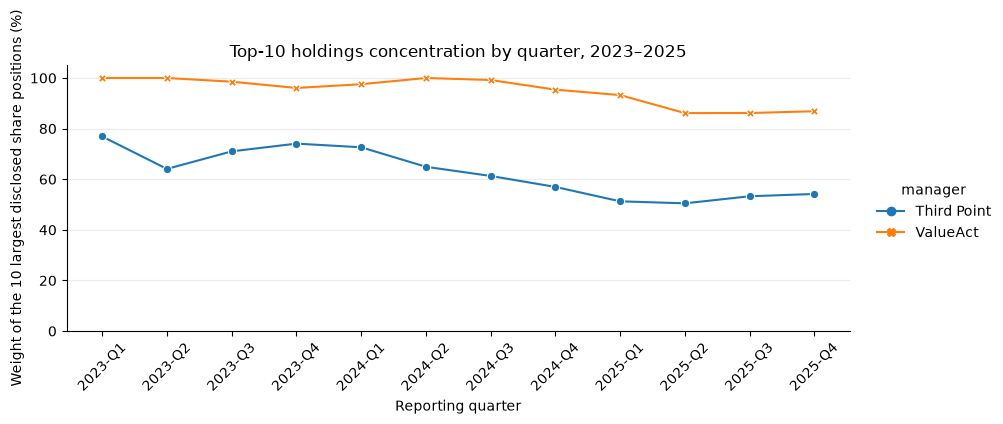

In [6]:
# Select the ten largest disclosed share positions for each manager and quarter.
# If fewer than ten positions were disclosed, include all of them.
top10_positions = (
    positions.sort_values("value_usd", ascending=False)
    .groupby(["manager", "quarter"], sort=False)
    .head(10)
)

# Sum the selected weights. Each weight was calculated using the total
# value of all included share positions for that manager and quarter.
top10_concentration = (
    top10_positions.groupby(["manager", "quarter"], as_index=False)
    .agg(
        top10_weight_pct=("weight_pct", "sum"),
        positions_included=("cusip", "size"),
    )
    .sort_values(["quarter", "manager"])
)

# Show the quarters in order so readers can see when concentration changed
# and when the gap between the managers widened or narrowed.
# Each marker represents one manager's observed value for one quarter.
concentration_chart = sns.relplot(
    data=top10_concentration,
    x="quarter",
    y="top10_weight_pct",
    hue="manager",
    hue_order=["Third Point", "ValueAct"],
    style="manager",
    markers=True,
    dashes=False,
    kind="line",
    estimator=None,
    sort=False,
    height=4,
    aspect=2.2,
)

# Keep the axis object under the name used by the export cell.
concentration_ax = concentration_chart.ax
_ = concentration_ax.set(
    title="Top-10 holdings concentration by quarter, 2023–2025",
    xlabel="Reporting quarter",
    ylabel="Weight of the 10 largest disclosed share positions (%)",
    ylim=(0, 105),
)
concentration_ax.tick_params(axis="x", labelrotation=45)
concentration_ax.grid(axis="y", alpha=0.25)
concentration_chart.tight_layout()

### What the concentration chart shows
I summed the weights of the ten largest disclosed share positions per manager and quarter. ValueAct’s top ten accounted for a larger share of its disclosed positions in all 12 quarters. Both managers reached their lowest concentration in 2025 Q2, at 86.1% for ValueAct and 50.5% for Third Point. I used all available positions when there were fewer than ten. ValueAct reaches 100% when all of its included positions fit within the top ten. The line chart made the shared low visible in time.
As a fund manager with over three decades' experience managing instituional funds, similar to the clients of the two funds analysed, I was surprised at the stock concentration level. My mandates required no position to be more than 5% above the relevant index weigh ( say MSCI) which is clearly not the requirement of these two funds who would be categorised as 'high conviction managers'. 
Time permitting, it would be interesting to investigate the two funds' performance but I would expect very high tracking error on both funds.


In [7]:
# Select ValueAct's two quarters and rank each security by reported value.
valueact = positions.loc[
    positions["manager"].eq("ValueAct")
    & positions["quarter"].isin(["2025-Q3", "2025-Q4"])
].copy()

valueact["rank"] = (
    valueact.groupby("quarter")["value_usd"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Match securities reported in both quarters by CUSIP.
q3 = valueact.loc[
    valueact["quarter"].eq("2025-Q3"), ["cusip", "rank", "weight_pct", "shares"]
]
q4 = valueact.loc[
    valueact["quarter"].eq("2025-Q4"), ["cusip", "issuer", "rank", "weight_pct", "shares"]
]
comparison = q3.merge(q4, on="cusip", suffixes=("_q3", "_q4"))

# Positive ranks gained means the security moved closer to first place.
comparison["ranks_gained"] = comparison["rank_q3"] - comparison["rank_q4"]
comparison["weight_change_pp"] = comparison["weight_pct_q4"] - comparison["weight_pct_q3"]
comparison["share_change_pct"] = 100 * (
    comparison["shares_q4"] / comparison["shares_q3"] - 1
)

comparison[
    ["issuer", "rank_q3", "rank_q4", "ranks_gained", "weight_change_pp", "share_change_pct"]
].sort_values("ranks_gained", ascending=False).round(2)

,issuer,rank_q3,rank_q4,ranks_gained,weight_change_pp,share_change_pct
8,ROCKET COS INC,7,3,4,2.55,55.07
11,TOAST INC,14,11,3,1.96,135.94
6,MONGODB INC,8,7,1,2.21,-33.59
5,LIVE NATION ENTERTAINMENT IN,15,14,1,-0.10,28.43
9,SALESFORCE INC,2,1,1,-0.29,3.31
1,CBRE GROUP INC,16,16,0,-0.09,0.00
10,SIMPSON MFG INC,11,12,-1,-0.03,21.87
3,META PLATFORMS INC,4,5,-1,0.33,36.34
0,AMAZON COM INC,1,2,-1,-1.81,-3.03
12,VISA INC,5,6,-1,-0.44,9.73


### What the comparison table shows
From 2025 Q3 to Q4, MongoDB’s reported share count fell 33.59%, yet its weight rose 2.21 percentage points. Roblox’s reported share count rose 39.52%, yet its weight fell 3.11 percentage points. Share-count changes and portfolio-weight changes can point in opposite directions because prices and the rest of the portfolio also move. For example in MongoDB case, the price of the shares most likely appreciated much higher than the overall portfolio performance during the relevant quarter, and the manager may have sold some shares to take advantage of the strong price appreciation in the quarter.


## Visualization techniques
**Scatter plot.** Each dot represents a security reported at both quarter ends. I compare the percentage change in shares with the change in weight in percentage points. The tooltip gives the exact figures. A time-series line works better when the question concerns one security over many quarters.
**Slope chart.** I use connected endpoints to show changes in rank for securities that were in the top ten at either endpoint and were reported in both quarters. This is my new-to-class technique. Crossings show which positions overtook one another. The chart is best for two snapshots, especially when there are few enough lines to follow.
**Paired horizontal bars.** Both managers’ weights share a zero baseline, which makes the weight difference for each common major holding easy to compare. The heatmap is easier to scan when the question spans many quarters.
**Heatmap.** Rows are securities and columns are reporting quarters. Color summarizes either a direction or a price change. The tiles reveal recurring patterns and gaps, while the tooltips supply the exact values.


In [8]:
# Set up the plot and show exact changes when hovering over a holding.
scatter = figure(
    title="ValueAct holdings changes, 2025 Q3 to Q4",
    x_axis_label="Change in reported shares (%)",
    y_axis_label="Change in weight (percentage points)",
    width=1000,
    height=460,
    # Bokeh adds a hover tool when tooltips are passed to figure().
    # Each @field refers to a column in the hovered dot's data source.
    tooltips=[
        ("Issuer", "@issuer"),
        ("CUSIP", "@cusip"),
        ("Change in shares", "@share_change_pct{0.00}%"),
        ("Change in weight", "@weight_change_pp{0.00} pp"),
        ("Rank", "@rank_q3 → @rank_q4"),
    ],
)

# Draw reference lines at zero on both axes.
for dimension in ("width", "height"):
    scatter.add_layout(
        Span(location=0, dimension=dimension, line_color="gray", line_dash="dashed")
    )

# Draw each holding separately so its legend entry can hide or restore it.
plot_data = comparison.sort_values("issuer")
legend_items = []

for index, color in enumerate(Category20[20][:len(plot_data)]):
    holding = plot_data.iloc[index:index + 1]
    dot = scatter.scatter(
        x="share_change_pct",
        y="weight_change_pp",
        source=holding,
        size=11,
        color=color,
    )
    legend_items.append(
        LegendItem(label=holding["issuer"].iloc[0], renderers=[dot])
    )

# Put the legend beside the plot so it leaves the dots visible.
legend = Legend(
    title="Holdings (click to show or hide)",
    items=legend_items,
    click_policy="hide",
)
scatter.add_layout(legend, "right")

show(scatter)

### What the first scatter plot shows
MongoDB and Roblox fall in opposite quadrants. The dashed lines at zero separate increases from decreases. The scatter makes the opposing patterns easier to spot, and the tooltip ties each point back to its issuer and exact values including chages in weight and ranking.


In [9]:
# Rank holdings by reported value within each manager and quarter.
ranked = positions.copy()
ranked["rank"] = (
    ranked.groupby(["manager", "quarter"])["value_usd"]
    .rank(method="min", ascending=False)
    .astype(int)
)

Each line in the slope chart follows one security from its earlier rank to its later rank. Rank 1 is at the top, so an upward line means the holding moved closer to first place. The chart includes securities reported in both quarters that ranked in the top 10 in either quarter. A holding that fell from 3rd to 12th still appears at its actual ranks. Two slope charts have been created, and savced, one for each manager.

In [10]:
# Choose the manager and ending quarter for this first slope chart.
slope_manager = "ValueAct"
slope_end = "2025-Q4"
slope_quarters = sorted(ranked["quarter"].unique())
end_index = slope_quarters.index(slope_end)

if end_index == 0:
    raise ValueError("Choose an ending quarter with a preceding quarter.")

slope_start = slope_quarters[end_index - 1]

# Use ranks calculated across all included positions within each quarter.
# Filtering to the top 10 before matching would hide holdings that moved
# into or out of the top 10 while remaining in the disclosed portfolio.
manager_ranks = ranked.loc[ranked["manager"].eq(slope_manager)]
earlier_ranks = manager_ranks.loc[
    manager_ranks["quarter"].eq(slope_start),
    ["cusip", "rank", "weight_pct"],
]
later_ranks = manager_ranks.loc[
    manager_ranks["quarter"].eq(slope_end),
    ["cusip", "issuer", "rank", "weight_pct"],
]

# Match by CUSIP to keep different securities from the same issuer distinct.
# A slope requires a rank in both quarters, so an entry or exit has no line.
slope_data = earlier_ranks.merge(
    later_ranks,
    on="cusip",
    suffixes=("_start", "_end"),
    validate="one_to_one",
)
slope_data = slope_data.loc[
    slope_data["rank_start"].le(10) | slope_data["rank_end"].le(10)
].sort_values(["rank_end", "issuer"]).copy()

if slope_data.empty:
    raise ValueError("No holdings reported in both quarters met the top-10 rule.")

# Positive ranks gained means the security moved closer to first place.
slope_data["ranks_gained"] = slope_data["rank_start"] - slope_data["rank_end"]
slope_data["x_start"] = 0
slope_data["x_end"] = 1
last_rank = int(slope_data[["rank_start", "rank_end"]].max().max())

# Reverse the y-axis so the best rank is at the top. The x-axis shows only
# the two observed quarter ends. Each line connects those two snapshots.
slope_plot = figure(
    title=f"{slope_manager} holdings ranks, {slope_start} to {slope_end}",
    x_range=(-0.15, 1.15),
    y_range=(last_rank + 0.5, 0.5),
    y_axis_label="Rank by reported position value",
    height=560,
    sizing_mode="stretch_width",
    tools="save,reset",
    tooltips=[
        ("Issuer", "@issuer"),
        (f"{slope_start} rank", "@rank_start"),
        (f"{slope_end} rank", "@rank_end"),
        ("Ranks gained", "@ranks_gained"),
        (f"{slope_start} weight", "@weight_pct_start{0.00}%"),
        (f"{slope_end} weight", "@weight_pct_end{0.00}%"),
    ],
)
slope_plot.xaxis.ticker = FixedTicker(ticks=[0, 1])
slope_plot.xaxis.major_label_overrides = {0: slope_start, 1: slope_end}
slope_plot.xgrid.grid_line_color = None

# Label every rank in short comparisons and thin the labels in longer ones.
rank_step = 1 if last_rank <= 16 else 2
slope_plot.yaxis.ticker = FixedTicker(
    ticks=list(range(1, last_rank + 1, rank_step))
)

# Give each holding a line and two endpoint dots. One legend entry controls
# all three so you can hide overlapping lines and inspect individual moves.
legend_items = []
colors = turbo(max(3, len(slope_data)))
duplicate_issuers = slope_data["issuer"].duplicated(keep=False)

for index, color in enumerate(colors[:len(slope_data)]):
    holding = slope_data.iloc[index:index + 1]

    line = slope_plot.segment(
        x0="x_start", y0="rank_start",
        x1="x_end", y1="rank_end",
        source=holding, color=color, line_width=2.5,
    )
    start_dot = slope_plot.scatter(
        x="x_start", y="rank_start", source=holding, color=color, size=8,
    )
    end_dot = slope_plot.scatter(
        x="x_end", y="rank_end", source=holding, color=color, size=8,
    )

    label = holding["issuer"].iloc[0]
    if duplicate_issuers.iloc[index]:
        label = f"{label} ({holding['cusip'].iloc[0]})"

    legend_items.append(
        LegendItem(label=label, renderers=[line, start_dot, end_dot])
    )

# Put the legend below the chart so the lines have the full available width.
slope_plot.add_layout(
    Legend(
        title="Holdings (click to show or hide)",
        items=legend_items,
        click_policy="hide",
        orientation="horizontal",
        ncols=2,
        label_text_font_size="9pt",
    ),
    "below",
)

# Keep the ValueAct chart available for the export cell.
slope_valueact = slope_plot
show(slope_valueact)

### What the ValueAct slope chart shows
The crossing lines show the change in order. Comparing these lines with the scatter highlights the difference between a change in rank and a change in shares.


In [11]:
# Choose the manager and ending quarter for this first slope chart.
slope_manager = "Third Point"
slope_end = "2025-Q4"
slope_quarters = sorted(ranked["quarter"].unique())
end_index = slope_quarters.index(slope_end)

if end_index == 0:
    raise ValueError("Choose an ending quarter with a preceding quarter.")

slope_start = slope_quarters[end_index - 1]

# Use ranks calculated across all included positions within each quarter.
# Filtering to the top 10 before matching would hide holdings that moved
# into or out of the top 10 while remaining in the disclosed portfolio.
manager_ranks = ranked.loc[ranked["manager"].eq(slope_manager)]
earlier_ranks = manager_ranks.loc[
    manager_ranks["quarter"].eq(slope_start),
    ["cusip", "rank", "weight_pct"],
]
later_ranks = manager_ranks.loc[
    manager_ranks["quarter"].eq(slope_end),
    ["cusip", "issuer", "rank", "weight_pct"],
]

# Match by CUSIP to keep different securities from the same issuer distinct.
# A slope requires a rank in both quarters, so an entry or exit has no line.
slope_data = earlier_ranks.merge(
    later_ranks,
    on="cusip",
    suffixes=("_start", "_end"),
    validate="one_to_one",
)
slope_data = slope_data.loc[
    slope_data["rank_start"].le(10) | slope_data["rank_end"].le(10)
].sort_values(["rank_end", "issuer"]).copy()

if slope_data.empty:
    raise ValueError("No holdings reported in both quarters met the top-10 rule.")

# Positive ranks gained means the security moved closer to first place.
slope_data["ranks_gained"] = slope_data["rank_start"] - slope_data["rank_end"]
slope_data["x_start"] = 0
slope_data["x_end"] = 1
last_rank = int(slope_data[["rank_start", "rank_end"]].max().max())

# Reverse the y-axis so the best rank is at the top. The x-axis shows only
# the two observed quarter ends. Each line connects those two snapshots.
slope_plot = figure(
    title=f"{slope_manager} holdings ranks, {slope_start} to {slope_end}",
    x_range=(-0.15, 1.15),
    y_range=(last_rank + 0.5, 0.5),
    y_axis_label="Rank by reported position value",
    height=560,
    sizing_mode="stretch_width",
    tools="save,reset",
    tooltips=[
        ("Issuer", "@issuer"),
        (f"{slope_start} rank", "@rank_start"),
        (f"{slope_end} rank", "@rank_end"),
        ("Ranks gained", "@ranks_gained"),
        (f"{slope_start} weight", "@weight_pct_start{0.00}%"),
        (f"{slope_end} weight", "@weight_pct_end{0.00}%"),
    ],
)
slope_plot.xaxis.ticker = FixedTicker(ticks=[0, 1])
slope_plot.xaxis.major_label_overrides = {0: slope_start, 1: slope_end}
slope_plot.xgrid.grid_line_color = None

# Label every rank in short comparisons and thin the labels in longer ones.
rank_step = 1 if last_rank <= 16 else 2
slope_plot.yaxis.ticker = FixedTicker(
    ticks=list(range(1, last_rank + 1, rank_step))
)

# Give each holding a line and two endpoint dots. One legend entry controls
# all three so you can hide overlapping lines and inspect individual moves.
legend_items = []
colors = turbo(max(3, len(slope_data)))
duplicate_issuers = slope_data["issuer"].duplicated(keep=False)

for index, color in enumerate(colors[:len(slope_data)]):
    holding = slope_data.iloc[index:index + 1]

    line = slope_plot.segment(
        x0="x_start", y0="rank_start",
        x1="x_end", y1="rank_end",
        source=holding, color=color, line_width=2.5,
    )
    start_dot = slope_plot.scatter(
        x="x_start", y="rank_start", source=holding, color=color, size=8,
    )
    end_dot = slope_plot.scatter(
        x="x_end", y="rank_end", source=holding, color=color, size=8,
    )

    label = holding["issuer"].iloc[0]
    if duplicate_issuers.iloc[index]:
        label = f"{label} ({holding['cusip'].iloc[0]})"

    legend_items.append(
        LegendItem(label=label, renderers=[line, start_dot, end_dot])
    )

# Put the legend below the chart so the lines have the full available width.
slope_plot.add_layout(
    Legend(
        title="Holdings (click to show or hide)",
        items=legend_items,
        click_policy="hide",
        orientation="horizontal",
        ncols=2,
        label_text_font_size="9pt",
    ),
    "below",
)

# Keep the Third Point chart available for the export cell.
slope_third_point = slope_plot
show(slope_third_point)

### What the Third Point slope chart shows
Union Pacific rose from 17th to fifth between 2025 Q3 and Q4, entering Third Point’s top ten. Upward lines show an improvement because rank one is at the top. The top-ten rule also explains why Danaher, which rose from 36th to 22nd, appears in the scatter but has no slope line in this view. In the same manner, any quarter's portfolio of each of the chosen managers can be examined.


In [12]:
# List the reporting quarters in chronological order.
quarters = sorted(positions["quarter"].unique())

# Rank each security against all included positions for that manager and quarter.
# Calculate ranks before matching quarters so new and exited positions can still
# affect the rank of a security that appears in both quarters.
ranked = positions.copy()
ranked["rank"] = (
    ranked.groupby(["manager", "quarter"])["value_usd"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Space the x-axis by log2(ending shares / starting shares) so large increases
# stay visible without crowding the smaller changes around zero.
# Each step doubles the ratio: half as many shares is -50%, the same number
# is 0%, twice as many is +100%, and four times as many is +300%.
share_ticks = list(range(-10, 11))
share_tick_labels = {
    tick: f"{100 * (2.0 ** tick - 1):+,.2f}".rstrip("0").rstrip(".") + "%"
    for tick in share_ticks
}
share_tick_labels[0] = "0%"


def make_scatter(manager, start, end):
    """Build the holdings comparison for one manager and two quarter ends."""
    manager_positions = ranked.loc[ranked["manager"].eq(manager)]

    # Keep reported value as well as share count so we can estimate share prices.
    earlier = manager_positions.loc[
        manager_positions["quarter"].eq(start),
        ["cusip", "shares", "value_usd", "weight_pct", "rank"],
    ]
    later = manager_positions.loc[
        manager_positions["quarter"].eq(end),
        ["cusip", "issuer", "shares", "value_usd", "weight_pct", "rank"],
    ]

    # Match by CUSIP to keep different securities from the same issuer distinct.
    # The inner join keeps only securities reported in both quarters.
    matched = earlier.merge(
        later,
        on="cusip",
        suffixes=("_start", "_end"),
        validate="one_to_one",
    )

    # Both share counts must be positive to calculate the log ratio and
    # divide reported position value by shares at each quarter end.
    matched = matched.loc[
        matched["shares_start"].gt(0) & matched["shares_end"].gt(0)
    ].copy()

    # Use the log ratio to position the dot and keep the exact percent change
    # for the hover tooltip.
    share_ratio = matched["shares_end"] / matched["shares_start"]
    matched["share_change_pct"] = 100 * (share_ratio - 1)
    matched["share_change_log2"] = share_ratio.map(log2)

    # Measure changes in portfolio weight in percentage points.
    matched["weight_change_pp"] = (
        matched["weight_pct_end"] - matched["weight_pct_start"]
    )

    # Estimate each quarter-end share price from the reported 13F position
    # value divided by the reported number of shares.
    matched["price_start"] = matched["value_usd_start"] / matched["shares_start"]
    matched["price_end"] = matched["value_usd_end"] / matched["shares_end"]

    # Measure price change during the selected quarter, from the previous
    # quarter end to the selected quarter end. For example, 2025 Q4 compares
    # September 30 with December 31, 2025.
    # Stock splits and reverse splits can distort the price and share-count
    # comparisons because the figures are unadjusted. The price calculation
    # excludes dividends and measures price change only.
    starting_price = matched["price_start"].where(matched["price_start"].gt(0))
    matched["price_change_pct"] = 100 * (matched["price_end"] / starting_price - 1)

    # Sort alphabetically so holdings are easy to find in the legend.
    matched = matched.sort_values("issuer")

    # Bokeh adds a hover tool when tooltips are passed to figure().
    # Each @field refers to a column in the hovered dot's data source.
    # For example, @shares_end{0,0} displays 600000 as 600,000.
    plot = figure(
        title=f"{manager} holdings changes, {start} to {end}",
        x_axis_label="Change in reported shares (logarithmic spacing)",
        y_axis_label="Change in weight (percentage points)",
        frame_height=420,
        sizing_mode="stretch_width",
        tooltips=[
            ("Issuer", "@issuer"),
            ("CUSIP", "@cusip"),
            (f"Shares at {start} end", "@shares_start{0,0}"),
            (f"Shares at {end} end", "@shares_end{0,0}"),
            ("Change in shares", "@share_change_pct{0,0.00}%"),
            (f"Implied price at {start} end", "$@price_start{0,0.00}"),
            (f"Implied price at {end} end", "$@price_end{0,0.00}"),
            (f"Implied price change during {end}", "@price_change_pct{0,0.00}%"),
            ("Change in weight", "@weight_change_pp{0.00} pp"),
            ("Rank", "@rank_start → @rank_end"),
        ],
    )

    # Label the transformed x-axis in percentages and align the grid with it.
    ticker = FixedTicker(ticks=share_ticks)
    plot.xaxis.ticker = ticker
    plot.xaxis.major_label_overrides = share_tick_labels
    plot.xgrid.ticker = ticker

    # Mark unchanged share count and unchanged weight with dashed lines.
    for dimension in ("width", "height"):
        plot.add_layout(
            Span(
                location=0,
                dimension=dimension,
                line_color="gray",
                line_dash="dashed",
            )
        )

    # Draw each holding separately so its legend entry can toggle its dot.
    # Generate enough colors to display every matched security.
    legend_items = []
    colors = turbo(max(3, len(matched)))
    repeated_issuers = matched["issuer"].duplicated(keep=False)

    for index in range(len(matched)):
        holding = matched.iloc[index:index + 1]
        dot = plot.scatter(
            x="share_change_log2",
            y="weight_change_pp",
            source=holding,
            size=10,
            color=colors[index],
        )

        # Add the CUSIP when more than one security shares the same issuer name.
        label = holding["issuer"].iloc[0]
        if repeated_issuers.iloc[index]:
            label = f"{label} ({holding['cusip'].iloc[0]})"

        legend_items.append(LegendItem(label=label, renderers=[dot]))

    # Put longer legends below the chart to preserve the plotting area.
    long_legend = len(legend_items) > 20
    legend = Legend(
        title="Holdings (click to show or hide)",
        items=legend_items,
        click_policy="hide",
        label_text_font_size="9pt",
        ncols=2 if long_legend else 1,
    )
    plot.add_layout(legend, "below" if long_legend else "right")

    return plot


# Create the dropdowns and open on ValueAct's latest quarter comparison.
managers = sorted(ranked["manager"].unique())
manager_select = Select(title="Manager", value="ValueAct", options=managers)
quarter_select = Select(
    title="Ending quarter",
    value=quarters[-1],
    options=quarters[1:],
)

# Build every consecutive-quarter comparison so the browser can switch
# views without rerunning Python.
plots = {}
for manager in managers:
    for start, end in zip(quarters[:-1], quarters[1:]):
        plot = make_scatter(manager, start, end)
        plot.visible = manager == manager_select.value and end == quarter_select.value
        plots[f"{manager}|{end}"] = plot

# Show only the chart that matches the current dropdown selections.
switch_plot = CustomJS(
    args=dict(
        plots=plots,
        manager_select=manager_select,
        quarter_select=quarter_select,
    ),
    code="""
        const selected = `${manager_select.value}|${quarter_select.value}`;
        for (const [key, plot] of Object.entries(plots)) {
            plot.visible = key === selected;
        }
    """,
)
manager_select.js_on_change("value", switch_plot)
quarter_select.js_on_change("value", switch_plot)

# Display both dropdowns above the selected chart.
show(column(
    bokeh_row(manager_select, quarter_select),
    *plots.values(),
    sizing_mode="stretch_width",
))

### What the interactive scatter shows
The manager and quarter controls let me look for unusual changes beyond the first example. I started with a linear share-change axis, but Danaher’s 1,100% increase crowded many points near zero. Logarithmic spacing made those points easier to inspect while keeping Danaher visible. The hover tooltip still reports the original percentage.


In [13]:
# compares Third Point and ValueAct across all 12 reporting quarters and measures each 
# weight change against the  preceding quarter. 
# The first quarter has weights and ranks, with blank changes because there’s no earlier quarter in the dataset.

# Rank each security within its manager and quarter before looking for overlap.
quarter_order = sorted(positions["quarter"].unique())
# Reuse the ranks from the shared ranking cell.
ranked_positions = ranked

# Move each quarter's weights forward one quarter for the lookup.
# An explicit quarter match prevents a holding that skipped a quarter
# from being compared with a position from two or more quarters earlier.
next_quarter = dict(zip(quarter_order[:-1], quarter_order[1:]))
previous_weights = ranked_positions[
    ["manager", "quarter", "cusip", "weight_pct"]
].rename(columns={"weight_pct": "previous_weight_pct"})
previous_weights["quarter"] = previous_weights["quarter"].map(next_quarter)
previous_weights = previous_weights.dropna(subset=["quarter"])

history = ranked_positions.merge(
    previous_weights,
    on=["manager", "quarter", "cusip"],
    how="left",
    validate="one_to_one",
)

# A missing prior position leaves the change blank.
history["weight_change_pp"] = (
    history["weight_pct"] - history["previous_weight_pct"]
)

# Match securities both managers reported in the same quarter.
comparison_columns = [
    "quarter", "cusip", "rank", "weight_pct", "weight_change_pp"
]
third_point = history.loc[
    history["manager"].eq("Third Point"), ["issuer", *comparison_columns]
]
valueact = history.loc[
    history["manager"].eq("ValueAct"), comparison_columns
]

common_history = third_point.merge(
    valueact,
    on=["quarter", "cusip"],
    suffixes=("_third_point", "_valueact"),
    validate="one_to_one",
)

# Flag a common security as major if it was in either manager's top 10.
common_history["best_rank"] = common_history[
    ["rank_third_point", "rank_valueact"]
].min(axis=1)
common_history["is_major"] = common_history["best_rank"].le(10)

# A positive gap means Third Point gave the security more weight that quarter.
common_history["weight_gap_pp"] = (
    common_history["weight_pct_third_point"]
    - common_history["weight_pct_valueact"]
)

# Keep the quarter-specific top-10 rule for the comparison table.
common_major = common_history.loc[common_history["is_major"]].sort_values(
    ["quarter", "best_rank", "issuer"]
)

# Show all quarters in the coverage check, including any with zero matches.
major_counts = (
    common_major.groupby("quarter").size()
    .reindex(quarter_order, fill_value=0)
    .rename("Common major holdings")
)
display(major_counts.to_frame())

# Display the holdings and each manager's quarter-to-quarter change.
display(common_major[[
    "quarter",
    "issuer",
    "rank_third_point",
    "rank_valueact",
    "weight_pct_third_point",
    "weight_pct_valueact",
    "weight_gap_pp",
    "weight_change_pp_third_point",
    "weight_change_pp_valueact",
]].round(2))

,Common major holdings
quarter,
2023-Q1,1
2023-Q2,0
2023-Q3,1
2023-Q4,1
2024-Q1,0
2024-Q2,0
2024-Q3,2
2024-Q4,3
2025-Q1,2


,quarter,issuer,rank_third_point,rank_valueact,weight_pct_third_point,weight_pct_valueact,weight_gap_pp,weight_change_pp_third_point,weight_change_pp_valueact
0,2023-Q1,SALESFORCE INC,11,4,2.62,11.34,-8.73,NaN,NaN
1,2023-Q3,DANAHER CORPORATION,3,12,9.29,0.66,8.63,0.14,NaN
2,2023-Q4,DANAHER CORPORATION,5,12,7.14,0.93,6.22,-2.14,0.27
3,2024-Q3,META PLATFORMS INC,8,7,4.20,2.91,1.28,-2.15,NaN
4,2024-Q3,LIVE NATION ENTERTAINMENT IN,10,8,3.45,2.67,0.77,1.98,NaN
5,2024-Q4,AMAZON COM INC,2,11,10.17,2.68,7.49,0.89,NaN
6,2024-Q4,META PLATFORMS INC,4,9,5.23,2.82,2.41,1.03,-0.09
7,2024-Q4,LIVE NATION ENTERTAINMENT IN,11,8,2.99,3.13,-0.14,-0.45,0.46
8,2025-Q1,AMAZON COM INC,2,11,7.03,2.34,4.70,-3.14,-0.35
9,2025-Q1,LIVE NATION ENTERTAINMENT IN,4,9,4.31,2.52,1.79,1.32,-0.61


### What the common holdings tables show
A common major holding is a security that both managers reported and that ranked in either manager’s top ten that quarter. Three quarters had no matches under that rule: 2023 Q2, 2024 Q1, and 2024 Q2. In 2025 Q4, Amazon and Rocket Companies qualified. Both carried more weight for ValueAct than for Third Point. The counts describe overlap under the top-ten rule.


In [14]:
# Choose a stable set of rows for both heatmaps. Include a security if both
# managers held it and it ranked in either manager's top 10 in any quarter.
# Use its most recent issuer name for the row label and CUSIP for matching.
heatmap_securities = (
    common_major.sort_values("quarter")
    .drop_duplicates("cusip", keep="last")[["cusip", "issuer"]]
    .sort_values("issuer")
)
security_order = heatmap_securities["cusip"].tolist()
issuer_labels = dict(zip(heatmap_securities["cusip"], heatmap_securities["issuer"]))

# Make a complete security-by-quarter grid. This gives missing observations
# a visible gray cell and keeps the rows aligned across the two heatmaps.
heatmap_grid = pd.MultiIndex.from_product(
    [security_order, quarter_order], names=["cusip", "quarter"]
).to_frame(index=False)
heatmap_grid["issuer"] = heatmap_grid["cusip"].map(issuer_labels)


# HEATMAP 1: Compare the direction of each manager's weight change.
# A weight is the security's share of a manager's included 13F positions.
# A weight can move because of share-count changes, price changes, or changes
# elsewhere in the portfolio. The colors describe weight changes only.
weight_fields = [
    "weight_change_pp_third_point",
    "weight_change_pp_valueact",
]
weight_heatmap = heatmap_grid.merge(
    common_history[["cusip", "quarter", *weight_fields]],
    on=["cusip", "quarter"],
    how="left",
    validate="one_to_one",
)

third_point_change = weight_heatmap[weight_fields[0]]
valueact_change = weight_heatmap[weight_fields[1]]

# Classify changes at the same two-decimal precision used in the tooltip.
# This keeps a change displayed as 0.00 from being colored as an increase
# or decrease. A blank means at least one manager lacks a comparable weight.
tp_direction = third_point_change.round(2)
va_direction = valueact_change.round(2)
comparable = tp_direction.notna() & va_direction.notna()

weight_heatmap["direction"] = "Comparison unavailable"
weight_heatmap.loc[comparable, "direction"] = "At least one unchanged"
weight_heatmap.loc[
    tp_direction.gt(0) & va_direction.gt(0), "direction"
] = "Both increased"
weight_heatmap.loc[
    tp_direction.lt(0) & va_direction.lt(0), "direction"
] = "Both decreased"
weight_heatmap.loc[
    (tp_direction.gt(0) & va_direction.lt(0))
    | (tp_direction.lt(0) & va_direction.gt(0)),
    "direction",
] = "Opposite directions"

direction_colors = {
    "Both increased": "#2166ac",
    "Both decreased": "#b2182b",
    "Opposite directions": "#7b3294",
    "At least one unchanged": "#f1df93",
    "Comparison unavailable": "#dedede",
}

# Format the hover values explicitly so missing values read as "Unavailable."
for field in weight_fields:
    weight_heatmap[f"{field}_label"] = weight_heatmap[field].map(
        lambda value: f"{value:+.2f} pp" if pd.notna(value) else "Unavailable"
    )


# HEATMAP 2: Estimate each security's quarterly price change.
# Divide reported position value by reported shares for each quarter-end.
# Require positive values and share counts for a usable price estimate.
prices = positions.loc[
    positions["shares"].gt(0) & positions["value_usd"].gt(0),
    ["manager", "cusip", "quarter", "shares", "value_usd"],
].copy()
prices["price_end"] = prices["value_usd"] / prices["shares"]

# Match the two endpoints using the same manager and CUSIP. Mapping the
# quarter explicitly prevents a missing quarter from creating a longer
# comparison period.
next_quarter = dict(zip(quarter_order[:-1], quarter_order[1:]))
prior_prices = prices[["manager", "cusip", "quarter", "price_end"]].rename(
    columns={"price_end": "price_start"}
)
prior_prices["quarter"] = prior_prices["quarter"].map(next_quarter)
prior_prices = prior_prices.dropna(subset=["quarter"])

price_changes = prices.merge(
    prior_prices,
    on=["manager", "cusip", "quarter"],
    validate="one_to_one",
)

# These are unadjusted implied prices. Stock splits and reverse splits can
# distort the comparison, and dividends are excluded from the calculation.
price_changes["price_change_pct"] = 100 * (
    price_changes["price_end"] / price_changes["price_start"] - 1
)

# Use one estimate per security and quarter. Prefer Third Point when it has
# both prices. Fall back to ValueAct when it has both and Third Point does not.
# Show the chosen filing manager on hover so the source is traceable.
price_changes["source_priority"] = price_changes["manager"].map(
    {"Third Point": 0, "ValueAct": 1}
)
price_changes = price_changes.sort_values("source_priority").drop_duplicates(
    ["cusip", "quarter"]
)
price_heatmap = heatmap_grid.merge(
    price_changes[[
        "cusip", "quarter", "manager", "price_start", "price_end", "price_change_pct"
    ]],
    on=["cusip", "quarter"],
    how="left",
    validate="one_to_one",
)
price_heatmap["manager"] = price_heatmap["manager"].fillna("Unavailable")

# Make the scale symmetric around 0% so equal gains and losses receive
# comparable color intensity. Gray marks a missing price comparison.
price_limit = price_heatmap["price_change_pct"].abs().max()
if pd.isna(price_limit) or price_limit == 0:
    price_limit = 1

price_mapper = LinearColorMapper(
    palette=["#b2182b", "#ef8a62", "#fddbc7", "#f7f7f7",
             "#d1e5f0", "#67a9cf", "#2166ac"],
    low=-price_limit,
    high=price_limit,
    nan_color="#dedede",
)

# Use the same axes and row order in both plots. CUSIPs define the rows
# internally, while issuer names appear on screen.
def make_heatmap(title, tooltips):
    plot = figure(
        title=title,
        x_range=quarter_order,
        y_range=list(reversed(security_order)),
        x_axis_location="above",
        height=max(300, 28 * len(security_order) + 130),
        sizing_mode="stretch_width",
        tools="save",
        tooltips=tooltips,
    )
    plot.yaxis.major_label_overrides = issuer_labels
    plot.xaxis.major_label_orientation = 0.7
    plot.grid.grid_line_color = None
    return plot


# Draw one group of tiles per direction so the legend explains the colors.
weight_plot = make_heatmap(
    "Did Third Point and ValueAct move their weights in the same direction?",
    [
        ("Issuer", "@issuer"),
        ("Ending quarter", "@quarter"),
        ("Third Point", "@weight_change_pp_third_point_label"),
        ("ValueAct", "@weight_change_pp_valueact_label"),
        ("Direction", "@direction"),
    ],
)
for direction, color in direction_colors.items():
    tiles = weight_heatmap.loc[weight_heatmap["direction"].eq(direction)]
    weight_plot.rect(
        x="quarter", y="cusip", width=0.96, height=0.96,
        source=tiles, fill_color=color, line_color=None,
        legend_label=direction,
    )
weight_legend = weight_plot.legend[0]
weight_plot.center.remove(weight_legend)
weight_legend.orientation = "horizontal"
weight_legend.ncols = 3
weight_plot.add_layout(weight_legend, "below")

# Draw the price heatmap and label its continuous scale in percentage units.
price_plot = make_heatmap(
    "Implied share-price change during each quarter (%)",
    [
        ("Issuer", "@issuer"),
        ("Ending quarter", "@quarter"),
        ("Filing source", "@manager"),
        ("Previous quarter-end price", "$@price_start{0,0.00}"),
        ("Selected quarter-end price", "$@price_end{0,0.00}"),
        ("Implied price change", "@price_change_pct{0,0.00}%"),
    ],
)
price_plot.rect(
    x="quarter", y="cusip", width=0.96, height=0.96,
    source=price_heatmap,
    fill_color={"field": "price_change_pct", "transform": price_mapper},
    line_color=None,
)
price_plot.add_layout(
    ColorBar(color_mapper=price_mapper, title="Price change (%)"), "right"
)

show(column(weight_plot, price_plot, sizing_mode="stretch_width"))

### What the weight and price heatmaps show
The weight heatmap distinguishes quarters when both managers increased or decreased a position’s weight, when they moved in opposite directions, and when a comparison was unavailable. In 2025 Q4, Amazon’s weight fell for both managers and Rocket’s rose for both.
The price heatmap adds the quarter-end price context. Gray means the necessary observations were unavailable. For each security-quarter estimate, both endpoints come from the same manager’s filing series.
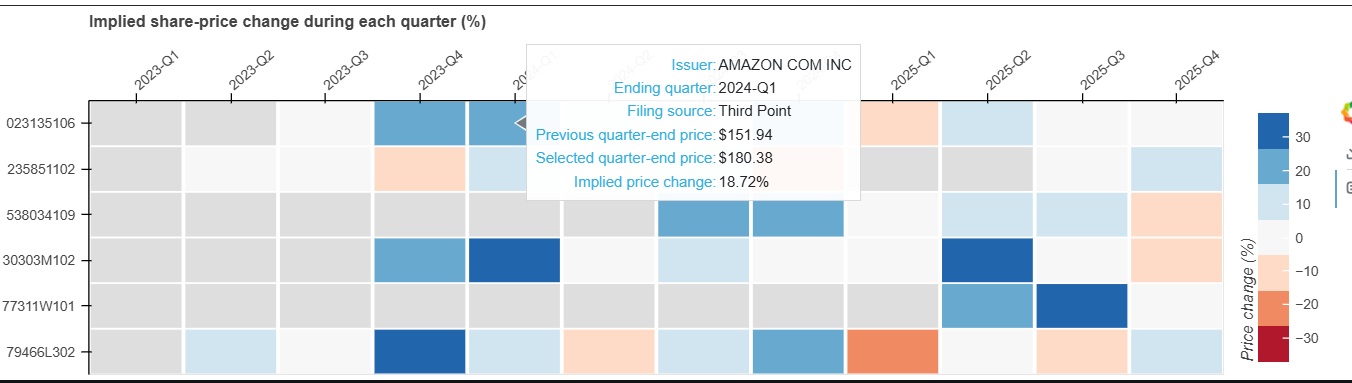

### What the combined heatmap shows
In 2025 Q4, both managers increased their reported Rocket Companies shares even though its implied share price edged down 0.10%. Third Point’s reported shares rose 137.88%, and ValueAct’s rose 55.07%. Amazon showed the opposite pattern: both managers’ reported share counts fell while its implied price rose 5.12%. These quarter-end comparisons show co-movement across reporting dates. Trade timing and motives are outside the scope of the filings.


### Did both managers change their share counts as prices rose or fell?

In [15]:
# Start with the same securities and quarters used in the first two heatmaps.
# Carry forward the implied price change, which was calculated using two
# consecutive quarter-end prices from the same manager's filings.
joint_heatmap = price_heatmap[
    ["cusip", "quarter", "issuer", "price_change_pct", "manager"]
].rename(columns={"manager": "price_source"}).copy()

# Get one share count per manager, security, and quarter.
# Keep positive counts so a percentage change has a valid starting value.
reported_shares = positions.loc[
    positions["shares"].gt(0),
    ["manager", "cusip", "quarter", "shares"],
].copy()

# Move each share count forward one quarter for the lookup. This ensures
# that a holding missing for a quarter is never compared across that gap.
prior_shares = reported_shares.rename(columns={"shares": "shares_prior"}).copy()
prior_shares["quarter"] = prior_shares["quarter"].map(next_quarter)
prior_shares = prior_shares.dropna(subset=["quarter"])

# Match the same manager and security across adjacent quarters.
# A security needs a reported position at both quarter-ends for comparison.
share_changes = reported_shares.merge(
    prior_shares,
    on=["manager", "cusip", "quarter"],
    validate="one_to_one",
)
share_changes["share_change_pct"] = 100 * (
    share_changes["shares"] / share_changes["shares_prior"] - 1
)

# Keep each manager's change in its own column so we can compare directions.
share_changes_wide = (
    share_changes.pivot(
        index=["cusip", "quarter"],
        columns="manager",
        values="share_change_pct",
    )
    .reindex(columns=["Third Point", "ValueAct"])
    .rename(columns={
        "Third Point": "third_point_share_change_pct",
        "ValueAct": "valueact_share_change_pct",
    })
    .rename_axis(columns=None)
    .reset_index()
)

joint_heatmap = joint_heatmap.merge(
    share_changes_wide,
    on=["cusip", "quarter"],
    how="left",
    validate="one_to_one",
)

# Classify directions at the same two-decimal precision shown on hover.
# Gray means at least one input is missing. Light blue means all inputs
# are available, but the managers moved differently or a change was flat.
tp_change = joint_heatmap["third_point_share_change_pct"].round(2)
va_change = joint_heatmap["valueact_share_change_pct"].round(2)
price_change = joint_heatmap["price_change_pct"].round(2)

complete = tp_change.notna() & va_change.notna() & price_change.notna()
both_up = tp_change.gt(0) & va_change.gt(0)
both_down = tp_change.lt(0) & va_change.lt(0)
price_up = price_change.gt(0)
price_down = price_change.lt(0)

joint_heatmap["pattern"] = "Comparison unavailable"
joint_heatmap.loc[complete, "pattern"] = "Mixed or flat"
joint_heatmap.loc[both_up & price_up, "pattern"] = "Both added | Price rose"
joint_heatmap.loc[both_up & price_down, "pattern"] = "Both added | Price fell"
joint_heatmap.loc[both_down & price_up, "pattern"] = "Both reduced | Price rose"
joint_heatmap.loc[both_down & price_down, "pattern"] = "Both reduced | Price fell"

# Use the same issuer order as the earlier heatmaps. Put the names directly
# on the categorical axis. Include a CUSIP only if two rows share a name.
axis_labels = heatmap_securities.set_index("cusip")["issuer"].copy()
duplicate_names = axis_labels.duplicated(keep=False)
axis_labels.loc[duplicate_names] = [
    f"{issuer} ({cusip})"
    for cusip, issuer in axis_labels.loc[duplicate_names].items()
]
joint_heatmap["security_label"] = joint_heatmap["cusip"].map(axis_labels)

# Format hover percentages explicitly so missing data reads as "Unavailable."
for field in (
    "third_point_share_change_pct",
    "valueact_share_change_pct",
    "price_change_pct",
):
    joint_heatmap[f"{field}_label"] = joint_heatmap[field].map(
        lambda value: f"{value:+.2f}%" if pd.notna(value) else "Unavailable"
    )

pattern_colors = {
    "Both added | Price rose": "#2166ac",
    "Both added | Price fell": "#008571",
    "Both reduced | Price rose": "#7b3294",
    "Both reduced | Price fell": "#b2182b",
    "Mixed or flat": "#d7e6f1",
    "Comparison unavailable": "#dedede",
}

# A tile compares changes between two quarter-end snapshots. The filings
# do not establish when trades took place. The share counts and implied
# prices are unadjusted for splits, and the price change excludes dividends.
joint_plot = figure(
    title="Reported share-count changes versus implied price changes",
    x_range=quarter_order,
    y_range=axis_labels.reindex(security_order).iloc[::-1].tolist(),
    x_axis_location="above",
    # Allow room for the tiles, quarter labels, title, and legend.
    height=max(420, 30 * len(security_order) + 220),
    sizing_mode="stretch_width",
    tools="save",
    # Bokeh adds a hover tool when tooltips are passed to figure().
    # Each @field refers to a column in the hovered dot's data source.
    tooltips=[
        ("Issuer", "@issuer"),
        ("Ending quarter", "@quarter"),
        ("Third Point share change", "@third_point_share_change_pct_label"),
        ("ValueAct share change", "@valueact_share_change_pct_label"),
        ("Implied price change", "@price_change_pct_label"),
        ("Price source", "@price_source"),
        ("Pattern", "@pattern"),
    ],
)
joint_plot.xaxis.major_label_orientation = 0.7
joint_plot.grid.grid_line_color = None

# Draw one group per pattern and place the legend beneath the chart.
legend_items = []
for pattern, color in pattern_colors.items():
    tiles = joint_heatmap.loc[joint_heatmap["pattern"].eq(pattern)]
    if tiles.empty:
        continue

    renderer = joint_plot.rect(
        x="quarter",
        y="security_label",
        width=0.96,
        height=0.96,
        source=tiles,
        fill_color=color,
        line_color=None,
    )
    legend_items.append(LegendItem(label=pattern, renderers=[renderer]))

joint_plot.add_layout(
    Legend(items=legend_items, orientation="horizontal", ncols=2),
    "below",
)

show(joint_plot)

# Record when the complete set of results was exported.
# Overwrite the timestamp file each time the export succeeds.
exported_at = datetime.now().astimezone().isoformat(timespec="seconds")
(results_dir / "last_exported.txt").write_text(
    f"Last successful export: {exported_at}\n",
    encoding="utf-8",
)
print(f"Results refreshed: {exported_at}")

Results refreshed: 2026-11-13T03:38:54+11:00


In [16]:
# Build one row per common major holding in each quarter.
# Keep quarters with no matches visible so the chart covers the full period.
bar_rows = []

for quarter in quarter_order:
    quarter_rows = (
        common_major.loc[common_major["quarter"].eq(quarter)]
        .sort_values(["best_rank", "issuer"])
        .copy()
    )

    if quarter_rows.empty:
        bar_rows.append(pd.DataFrame({
            "quarter": [quarter],
            "axis_label": [f"{quarter}  |  No common major holdings"],
        }))
    else:
        quarter_rows["axis_label"] = quarter + "  |  " + quarter_rows["issuer"]
        bar_rows.append(quarter_rows)

bar_data = pd.concat(bar_rows, ignore_index=True)

# Use numeric row positions so the two bars sit side by side vertically.
# Reverse the y-axis to put the earliest quarter at the top.
bar_data["issuer_row"] = bar_data.index
bar_data["third_point_row"] = bar_data["issuer_row"] - 0.18
bar_data["valueact_row"] = bar_data["issuer_row"] + 0.18

# Use one weight scale for all quarters so bar lengths are comparable.
largest_weight = common_major[
    ["weight_pct_third_point", "weight_pct_valueact"]
].max().max()
x_end = largest_weight * 1.10 if pd.notna(largest_weight) else 1

common_bars = figure(
    title="Common major holdings by portfolio weight, 2023–2025",
    x_axis_label="Weight in each manager’s disclosed share positions (%)",
    x_range=(0, x_end),
    y_range=(len(bar_data) - 0.5, -0.5),
    height=max(420, 32 * len(bar_data) + 150),
    sizing_mode="stretch_width",
    tools="save",
)

# Label each pair with its quarter and issuer. Draw bars only for actual matches.
common_bars.yaxis.ticker = FixedTicker(ticks=bar_data["issuer_row"].tolist())
common_bars.yaxis.major_label_overrides = dict(
    zip(bar_data["issuer_row"], bar_data["axis_label"])
)
common_bars.ygrid.grid_line_color = None
matched_bars = bar_data.loc[bar_data["weight_pct_third_point"].notna()]

third_point_bars = common_bars.hbar(
    y="third_point_row",
    left=0,
    right="weight_pct_third_point",
    height=0.30,
    source=matched_bars,
    color="#2166ac",
)
valueact_bars = common_bars.hbar(
    y="valueact_row",
    left=0,
    right="weight_pct_valueact",
    height=0.30,
    source=matched_bars,
    color="#d97706",
)

# Hovering over either bar shows both weights and the difference.
common_bars.add_tools(HoverTool(
    renderers=[third_point_bars, valueact_bars],
    tooltips=[
        ("Quarter", "@quarter"),
        ("Issuer", "@issuer"),
        ("Third Point weight", "@weight_pct_third_point{0.00}%"),
        ("ValueAct weight", "@weight_pct_valueact{0.00}%"),
        ("Third Point minus ValueAct", "@weight_gap_pp{0.00} pp"),
    ],
))

common_bars.add_layout(
    Legend(
        items=[
            LegendItem(label="Third Point", renderers=[third_point_bars]),
            LegendItem(label="ValueAct", renderers=[valueact_bars]),
        ],
        orientation="horizontal",
    ),
    "above",
)

show(common_bars)

### Using the linked dashboard 

The **Manager** dropdown switches the scatter plot and slope chart between Third Point and ValueAct. The scatter plot shows changes in reported shares and portfolio weight, while the slope chart shows how holdings moved in rank.

The **Ending quarter** dropdown updates the scatter plot, slope chart, and paired bars together. For example, choosing **2025 Q4** compares the Q3 and Q4 filings in the scatter and slope charts. The paired bars show both managers’ weights at the end of Q4, and the heatmap outlines the Q4 column while keeping all 12 quarters visible.

When no shared holding ranked in either manager’s top 10, the paired bar panel displays a message. The other views still show the selected quarter.

In [ ]:

def make_dashboard_slope(manager, start, end):
    """Show rank changes for securities reported in both quarters."""
    ranks = ranked.loc[ranked["manager"].eq(manager)]
    earlier = ranks.loc[
        ranks["quarter"].eq(start), ["cusip", "rank", "weight_pct"]
    ]
    later = ranks.loc[
        ranks["quarter"].eq(end), ["cusip", "issuer", "rank", "weight_pct"]
    ]

    # Rank comes from the full portfolio. Keep securities that were in the
    # top 10 at either endpoint, even if their rank fell below 10 later.
    slopes = earlier.merge(
        later, on="cusip", suffixes=("_start", "_end"), validate="one_to_one"
    )
    slopes = slopes.loc[
        slopes["rank_start"].le(10) | slopes["rank_end"].le(10)
    ].copy()
    slopes["left"] = 0
    slopes["right"] = 1
    slopes["color"] = turbo(max(3, len(slopes)))[:len(slopes)]

    last_rank = max(10, int(slopes[["rank_start", "rank_end"]].max().max())) if len(slopes) else 10
    plot = figure(
        title=f"{manager} holding ranks, {start} to {end}",
        x_range=(-0.15, 1.15),
        y_range=(last_rank + 0.5, 0.5),
        y_axis_label="Rank by reported position value",
        height=380,
        sizing_mode="stretch_width",
        tools="save",
    )
    plot.xaxis.ticker = FixedTicker(ticks=[0, 1])
    plot.xaxis.major_label_overrides = {0: start, 1: end}
    plot.xgrid.grid_line_color = None

    if slopes.empty:
        plot.title.text += " · No matching top-10 holdings"
        return plot

    # Give the line and both endpoints the same data and color.
    source = ColumnDataSource(slopes)
    lines = plot.segment(
        x0="left", y0="rank_start", x1="right", y1="rank_end",
        source=source, color="color", line_width=2.5,
    )
    start_dots = plot.scatter(
        x="left", y="rank_start", source=source, color="color", size=8,
    )
    end_dots = plot.scatter(
        x="right", y="rank_end", source=source, color="color", size=8,
    )
    plot.add_tools(HoverTool(
        renderers=[lines, start_dots, end_dots],
        tooltips=[
            ("Issuer", "@issuer"),
            ("Rank", "@rank_start → @rank_end"),
            (f"Weight in {start}", "@weight_pct_start{0.00}%"),
            (f"Weight in {end}", "@weight_pct_end{0.00}%"),
        ],
    ))
    return plot


# Use the same weight scale in every quarter so a bar of a given length
# always represents the same weight, even after changing the dropdown.
weight_columns = ["weight_pct_third_point", "weight_pct_valueact"]
largest_weight = common_major[weight_columns].max().max()
bar_limit = largest_weight * 1.10 if pd.notna(largest_weight) and largest_weight > 0 else 1


def make_dashboard_bars(quarter):
    """Compare both managers' weights in common major holdings."""
    bars = (
        common_major.loc[common_major["quarter"].eq(quarter)]
        .sort_values(["best_rank", "issuer"])
        .reset_index(drop=True)
    )

    plot = figure(
        title=f"Common major holdings, {quarter}",
        x_axis_label="Weight in disclosed share positions (%)",
        x_range=(0, bar_limit),
        y_range=(max(0.5, len(bars) - 0.5), -0.5),
        height=max(260, 55 * len(bars) + 130),
        sizing_mode="stretch_width",
        tools="save",
    )

        # Show a message when no holdings qualify for the paired bars.
    if bars.empty:
        plot.title.text = f"No common major holdings in {quarter}"
        plot.axis.visible = False
        plot.grid.grid_line_color = None
        plot.text(
            x=[bar_limit / 2],
            y=[0],
            text=["No shared holdings ranked in either manager’s top 10."],
            text_align="center",
            text_baseline="middle",
            text_color="#555555",
        )
        return plot

    # Offset the bars above and below each issuer's axis label.
    bars["row_position"] = bars.index
    bars["third_point_row"] = bars["row_position"] - 0.18
    bars["valueact_row"] = bars["row_position"] + 0.18
    plot.yaxis.ticker = FixedTicker(ticks=bars["row_position"].tolist())
    plot.yaxis.major_label_overrides = dict(zip(bars["row_position"], bars["issuer"]))
    plot.ygrid.grid_line_color = None

    source = ColumnDataSource(bars)
    tp_bars = plot.hbar(
        y="third_point_row", left=0, right="weight_pct_third_point",
        height=0.30, source=source, color="#2166ac",
    )
    va_bars = plot.hbar(
        y="valueact_row", left=0, right="weight_pct_valueact",
        height=0.30, source=source, color="#d97706",
    )
    plot.add_layout(Legend(
        items=[
            LegendItem(label="Third Point", renderers=[tp_bars]),
            LegendItem(label="ValueAct", renderers=[va_bars]),
        ],
        orientation="horizontal",
    ), "above")
    plot.add_tools(HoverTool(
        renderers=[tp_bars, va_bars],
        tooltips=[
            ("Issuer", "@issuer"),
            ("Third Point weight", "@weight_pct_third_point{0.00}%"),
            ("ValueAct weight", "@weight_pct_valueact{0.00}%"),
            ("Third Point minus ValueAct", "@weight_gap_pp{0.00} pp"),
        ],
    ))
    return plot


# Start with the latest quarter. The first reporting quarter remains visible
# in the heatmap, but the dropdown starts at Q2 because changes need a baseline.
dashboard_managers = sorted(ranked["manager"].unique())
dashboard_manager = Select(title="Manager", value="ValueAct", options=dashboard_managers)
dashboard_quarter = Select(
    title="Ending quarter", value=quarter_order[-1], options=quarter_order[1:]
)

# Prepare the figures in Python. Once exported, the browser can switch views
# using the embedded data without asking the notebook to run again.
manager_quarter_keys = []
scatter_views = []
slope_views = []
bar_views = []

for start, end in zip(quarter_order[:-1], quarter_order[1:]):
    bar_view = make_dashboard_bars(end)
    bar_view.visible = end == dashboard_quarter.value
    bar_views.append(bar_view)

    for manager in dashboard_managers:
        scatter_view = make_scatter(manager, start, end)
        slope_view = make_dashboard_slope(manager, start, end)
        selected = manager == dashboard_manager.value and end == dashboard_quarter.value
        scatter_view.visible = selected
        slope_view.visible = selected

        manager_quarter_keys.append(f"{manager}|{end}")
        scatter_views.append(scatter_view)
        slope_views.append(slope_view)

# Outline the selected quarter's tiles while keeping all 12 columns visible.
# Restrict hover to the original tiles so the outlines don't intercept it.
heatmap_rows = list(joint_plot.y_range.factors)
for hover in joint_plot.select(type=HoverTool):
    hover.renderers = list(joint_plot.renderers)

highlight_source = ColumnDataSource(data={
    "quarter": [dashboard_quarter.value] * len(heatmap_rows),
    "security": heatmap_rows,
})
joint_plot.rect(
    x="quarter", y="security", width=0.97, height=0.97,
    source=highlight_source, fill_alpha=0,
    line_color="#202020", line_width=2,
)

# Both dropdowns use the same callback. The manager affects the scatter and
# slope. The quarter also switches the paired bars and moves the outlines.
update_dashboard = CustomJS(
    args=dict(
        manager_control=dashboard_manager,
        quarter_control=dashboard_quarter,
        keys=manager_quarter_keys,
        scatter_views=scatter_views,
        slope_views=slope_views,
        bar_views=bar_views,
        bar_quarters=quarter_order[1:],
        highlight_source=highlight_source,
    ),
    # VS Code colors it like a string because Python passes it as text
    #  to Bokeh’s CustomJS. Bokeh then runs it as JavaScript in the browser.

    # That block is what makes the dropdowns update the scatter plot, 
    # slope chart, paired bars, and heatmap outline.
    code="""
        const selected = `${manager_control.value}|${quarter_control.value}`;
        for (let i = 0; i < keys.length; i++) {
            scatter_views[i].visible = keys[i] === selected;
            slope_views[i].visible = keys[i] === selected;
        }
        for (let i = 0; i < bar_quarters.length; i++) {
            bar_views[i].visible = bar_quarters[i] === quarter_control.value;
        }
        highlight_source.data = {
            quarter: highlight_source.data.security.map(() => quarter_control.value),
            security: highlight_source.data.security,
        };
    """,
)
dashboard_manager.js_on_change("value", update_dashboard)
dashboard_quarter.js_on_change("value", update_dashboard)

# Stack the views on one scrollable page under a single set of controls.
linked_dashboard = column(
    bokeh_row(dashboard_manager, dashboard_quarter),
    *scatter_views,
    *slope_views,
    *bar_views,
    joint_plot,
    sizing_mode="stretch_width",
)
show(linked_dashboard)

##  Building and exploring the linked dashboard
I started with one quarter pair for ValueAct, then linked the scatter, slope chart, paired bars, and heatmap. Changing **Ending quarter** updates the first three views and moves the heatmap outline. Changing **Manager** updates the scatter and slope chart. The bars keep both managers visible.
When I selected **ValueAct and 2025 Q4**, I could trace Rocket Companies across the views. The slope showed it rise from seventh to third. Hovering in the scatter showed a 55.07% increase in reported shares. The bars showed how much more weight ValueAct assigned it, and the heatmap showed that both managers increased shares while the implied price edged down. The linked quarter selection let me verify that each view described the same reporting interval.
I did not want to clutter this Notebook but the linked dashboard can be explored further in the public GitHub repository.


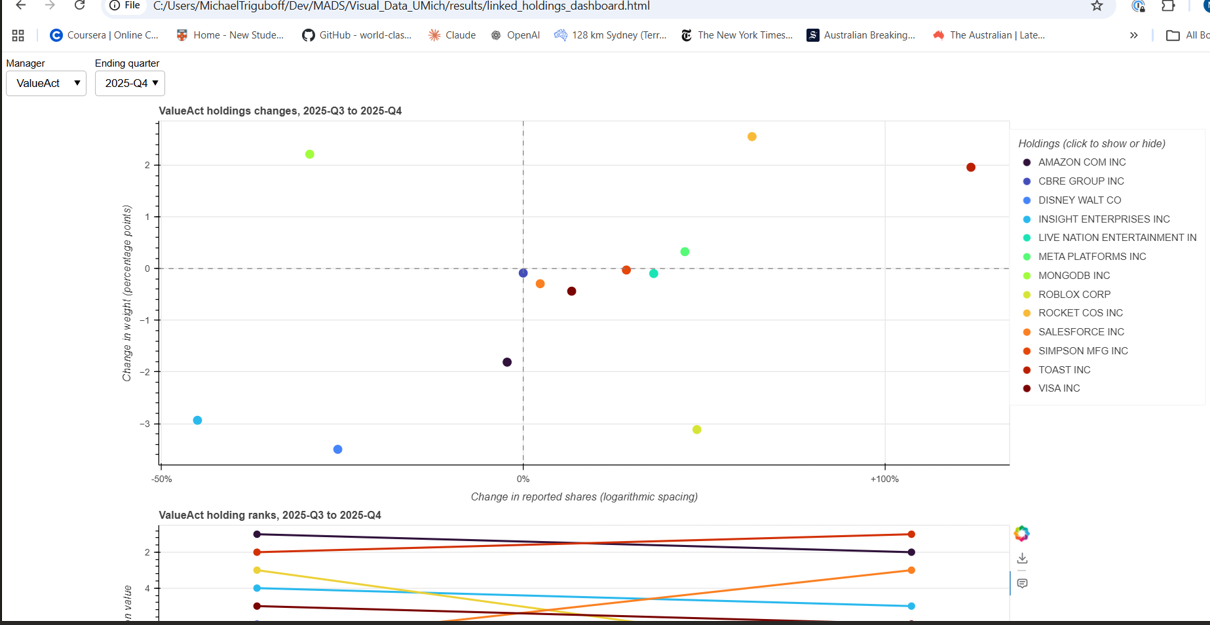
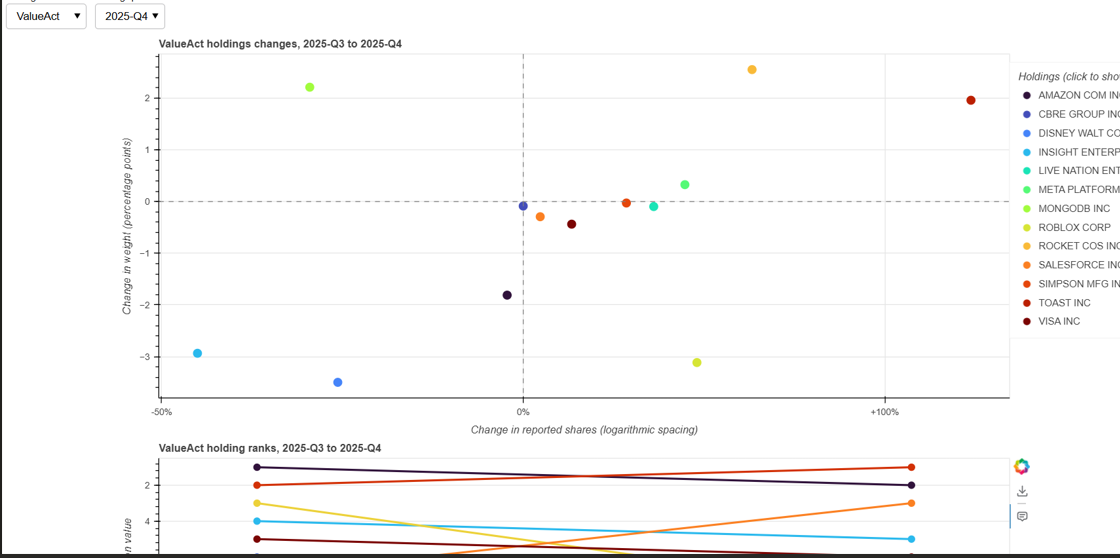
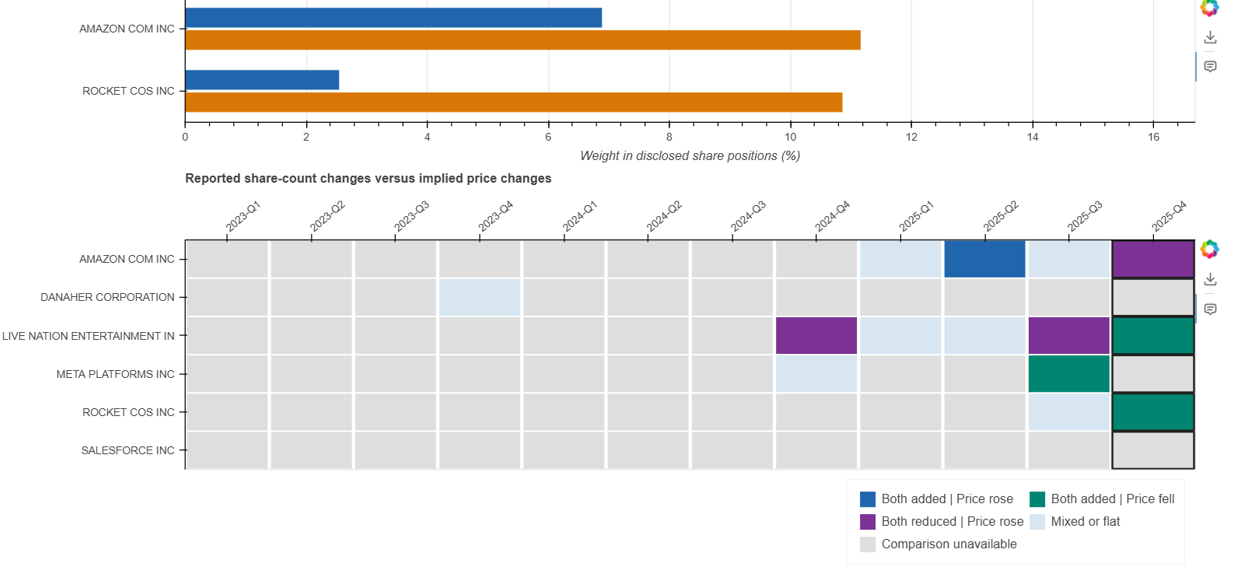

In [18]:
# temporary cell to check error message when no common holdings
for view in [*scatter_views, *slope_views, *bar_views]:
    if not view.renderers:
        print(view.id, view.title.text)

##  AI log and troubleshooting
I used ChatGPT to brainstorm the dashboard, draft code, and troubleshoot. I checked the suggestions against the notebook output and the standalone HTML. The interaction was reiterative and depended on my examination of the various visualisations as well as my experience as a fund manager ( what I would ask in examining a portfolio). Examples of trouble shooting interaction are noted below.

**Entry 1 — Bokeh layout name collision**
- *Tool and task*: ChatGPT, to place the dropdowns side by side.
- *What happened*: The suggested code imported Bokeh’s `row` function under the same name as the variable in my XML loop.
- *What was wrong and how I noticed*: The notebook raised a TypeError because `row` referred to an XML element when I called it.
- *What I did*: I imported the function as `bokeh_row` and reran the dashboard.
**Entry 2 — Scatter legend took up too much space**
- *Tool and task*: ChatGPT, to add a clickable holdings legend.
- *What happened*: The initial design put a long, two-column legend on the right.
- *What was wrong and how I noticed*: For Third Point in 2024 Q2, the legend compressed the scatter plot into a narrow strip.
- *What I did*: I placed longer legends below the chart and kept shorter legends beside it.
**Entry 3 — Standalone HTML export failed**
- *Tool and task*: ChatGPT, to save charts and the dashboard as standalone HTML.
- *What happened*: The suggested export reused Bokeh chart models that had already been displayed.
- *What was wrong and how I noticed*: `file_html()` raised a RuntimeError about a model already belonging to a document.
- *What I did*: I used `_always_new=True` to export through a temporary Bokeh document, reran the cell, and checked the resulting HTML in Chrome.


### Exporting the dashboard, charts, and data

The export cell saves **nine HTML files, ten CSV tables, one PNG, and one timestamp file** in the `results` folder. Rerunning the export replaces the files with the same names. The timestamp is updated after all charts and tables have been saved successfully.

#### Dashboard and interactive charts

The HTML files include the chart data and Bokeh’s JavaScript, so they can be opened in a browser with their interactive features intact.

| HTML file | Contents |
|---|---|
| `linked_holdings_dashboard.html` | Main dashboard with a scatter plot, slope chart, paired bars, and heatmap. The manager and ending-quarter dropdowns link the views. |
| `scatter_valueact_2025_q4.html` | ValueAct’s changes in reported shares and portfolio weight from Q3 to Q4 2025. |
| `scatter_interactive.html` | Scatter plot with manager and ending-quarter dropdowns. |
| `heatmap_manager_weight_changes.html` | Whether the two managers changed the weights of common holdings in the same or opposite directions. |
| `heatmap_implied_price_changes.html` | Implied quarterly share-price changes for the securities included in the heatmaps. |
| `heatmap_share_changes_vs_price.html` | Whether both managers added or reduced reported shares while the implied share price rose or fell. |
| `slope_valueact_2025_q4.html` | ValueAct’s holdings rank changes from Q3 to Q4 2025. |
| `slope_third_point_2025_q4.html` | Third Point’s holdings rank changes from Q3 to Q4 2025. |
| `common_holdings_bars_all_quarters.html` | Paired bars comparing both managers’ weights in common major holdings across all 12 quarters. |

#### Data tables

| CSV file | Contents |
|---|---|
| `reported_holdings.csv` | Holdings rows extracted from the original SEC 13F filings and ValueAct’s amendment. |
| `share_positions_with_weights.csv` | Share positions grouped by manager, quarter, and security, with each position’s weight. |
| `holdings_counts_by_quarter.csv` | Number of reported holdings rows per manager and quarter. |
| `valueact_2025_q4_comparison.csv` | Ranks, weights, share counts, and their changes for ValueAct securities reported in both Q3 and Q4 2025. |
| `common_major_counts_by_quarter.csv` | Number of securities held by both managers that ranked in either manager’s top 10, including quarters with zero matches. |
| `common_major_holdings.csv` | Ranks, weights, weight gaps, and quarterly weight changes for common major holdings. |
| `heatmap_weight_data.csv` | Manager weight changes and direction categories used in the weight heatmap. |
| `heatmap_price_data.csv` | Implied quarter-end prices, quarterly price changes, and the filing manager used as the price source. |
| `heatmap_share_changes_vs_price_data.csv` | Reported share-count changes, implied price changes, and the combined direction category for each heatmap tile. |

In [19]:
# Create the results folder if it does not already exist.
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

# Assemble the standalone scatter view with both dropdowns.
interactive_scatter = column(
    bokeh_row(manager_select, quarter_select),
    *plots.values(),
    sizing_mode="stretch_width",
)

# Export each chart as standalone HTML with Bokeh's JavaScript embedded.
charts = {
    "scatter_valueact_2025_q4": scatter,
    "scatter_interactive": interactive_scatter,
    "heatmap_manager_weight_changes": weight_plot,
    "heatmap_implied_price_changes": price_plot,
    "heatmap_share_changes_vs_price": joint_plot,
    "slope_valueact_2025_q4": slope_valueact,
    "slope_third_point_2025_q4": slope_third_point,
    "common_holdings_bars_all_quarters": common_bars,
    "linked_holdings_dashboard": linked_dashboard,
}

for name, chart in charts.items():
    output_path = results_dir / f"{name}.html"
    title = name.replace("_", " ").title()

    # Use a temporary Bokeh document to export charts displayed in the notebook.
    html = file_html(chart, INLINE, title=title, _always_new=True)
    output_path.write_text(html, encoding="utf-8")
    print(f"Saved {output_path}")

# Select the columns shown in the common-holdings table.
# CUSIP stays in the underlying holdings data for matching.
common_major_table = common_major[[
    "quarter",
    "issuer",
    "rank_third_point",
    "rank_valueact",
    "weight_pct_third_point",
    "weight_pct_valueact",
    "weight_gap_pp",
    "weight_change_pp_third_point",
    "weight_change_pp_valueact",
]].round(2)

# Convert quarter indexes to columns where needed before writing the CSVs.
tables = {
    "reported_holdings": holdings,
    "share_positions_with_weights": positions,
    "holdings_counts_by_quarter": quarter_counts.reset_index(),
    "valueact_2025_q4_comparison": comparison,
    "common_major_counts_by_quarter": major_counts.reset_index(),
    "common_major_holdings": common_major_table,
    "heatmap_weight_data": weight_heatmap,
    "heatmap_price_data": price_heatmap,
    "heatmap_share_changes_vs_price_data": joint_heatmap,
    "top10_concentration_by_quarter": top10_concentration,
}

for name, table in tables.items():
    output_path = results_dir / f"{name}.csv"
    table.to_csv(output_path, index=False, encoding="utf-8-sig")
    print(f"Saved {output_path}")

# Save the Seaborn concentration chart as a PNG.
concentration_path = results_dir / "top10_concentration.png"
concentration_ax.figure.savefig(concentration_path, dpi=180, bbox_inches="tight")
print(f"Saved {concentration_path}")

# Refresh the timestamp only after all HTML, CSV, and PNG writes succeed.
exported_at = datetime.now().astimezone().isoformat(timespec="seconds")
timestamp_path = results_dir / "last_exported.txt"
timestamp_path.write_text(
    f"Last successful export: {exported_at}\n",
    encoding="utf-8",
)

print(f"\nResults folder: {results_dir.resolve()}")
print(f"Last successful export: {exported_at}")

Saved results\scatter_valueact_2025_q4.html
Saved results\scatter_interactive.html
Saved results\heatmap_manager_weight_changes.html
Saved results\heatmap_implied_price_changes.html
Saved results\heatmap_share_changes_vs_price.html
Saved results\slope_valueact_2025_q4.html
Saved results\slope_third_point_2025_q4.html
Saved results\common_holdings_bars_all_quarters.html
Saved results\linked_holdings_dashboard.html
Saved results\reported_holdings.csv
Saved results\share_positions_with_weights.csv
Saved results\holdings_counts_by_quarter.csv
Saved results\valueact_2025_q4_comparison.csv
Saved results\common_major_counts_by_quarter.csv
Saved results\common_major_holdings.csv
Saved results\heatmap_weight_data.csv
Saved results\heatmap_price_data.csv
Saved results\heatmap_share_changes_vs_price_data.csv
Saved results\top10_concentration_by_quarter.csv
Saved results\top10_concentration.png

Results folder: C:\Users\MichaelTriguboff\Dev\MADS\Visual_Data_UMich\results
Last successful export: 20

### What the export output confirms
The printed file paths identify the dashboard, supporting plots, and data tables that were saved. The timestamp is written after the chart and table exports succeed. The linked dashboard HTML is the file I submit alongside the narrative notebook and video link.


##  Reproducing and sharing the dashboard
Keep `requirements.txt` and the extracted SEC filing folders beside the notebook. On Windows, open PowerShell in the project folder and run:
~~~powershell
py -3.12 -m venv .venv
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
~~~
Select the new Python environment as the notebook kernel and run the cells in order. The final cell writes nine HTML files, ten CSVs, the concentration PNG, and the latest successful export timestamp to `results`. The filenames stay fixed, so reruns replace the current outputs.
Open `results/linked_holdings_dashboard.html` directly in a browser. I checked in Chrome that the manager and quarter controls updated the linked views and that Danaher’s tooltip displayed the expected figures. The GitHub link is [Public GitHub repository](https://github.com/MichaelTriguboff/SIADS521_Ass3)
